## Tugas 2 Analisis Numerik
## Perhitungan Volume Kedua Lambung Kapal

**Nama:** Muhammad Haikal Ardiansyah

**NPM:** 25083010032

**Mata Kuliah:** Analisis Numerik  

### Link Github

PERHITUNGAN VOLUME KEDUA LAMBUNG KAPAL
=======================================

Berdasarkan instruksi:
1. Satu dash-kosong = 5+5 cm = 10 cm (skala pengukuran)
2. Lantai kapal datar (tidak ada keel), tampak depan persegi panjang
3. Volume reserve buoyancy tidak dihitung
4. Yang dihitung: volume kedua lambung kapal

Karena gambar teknis tidak tersedia dalam file, kode ini dibuat FLEKSIBEL
sehingga dapat disesuaikan dengan dimensi aktual dari gambar kapal.

INTERPRETASI:
- "Kedua lambung kapal" menunjukkan ini adalah kapal katamaran (2 lambung)
- "Satu dash-kosong adalah 5+5 cm" = setiap tanda dash dan kosong mewakili 5 cm,
  sehingga total 1 unit = 10 cm (ini adalah skala pengukuran pada gambar)
- Volume dihitung dengan integrasi/penjumlahan volumetrik sepanjang kapal
"""


PERHITUNGAN VOLUME KEDUA LAMBUNG KAPAL

[SKALA] 1 dash-kosong = 5+5 cm = 10 cm = 0.1 m
Asumsi:
  - Lantai kapal datar (tidak ada keel)
  - Tampak depan persegi panjang
  - Volume reserve buoyancy tidak dihitung

[DIMENSI DARI GAMBAR]
  Panjang total  : 40 kotak = 4.00 m
  Lebar maksimum : 5 kotak = 0.50 m
  Tinggi lambung : 4 kotak = 0.40 m
  Jumlah titik profil lebar: 6

[KONVERSI KE METER]
  Titik 1: x = 0.00 m, lebar = 0.00 m
  Titik 2: x = 0.50 m, lebar = 0.25 m
  Titik 3: x = 1.00 m, lebar = 0.50 m
  Titik 4: x = 3.00 m, lebar = 0.50 m
  Titik 5: x = 3.50 m, lebar = 0.40 m
  Titik 6: x = 4.00 m, lebar = 0.20 m
  Tinggi konstan = 0.40 m

[PERHITUNGAN VOLUME 1 LAMBUNG]
------------------------------------------------------------
Segmen  Δx (m)    b_rata (m)    Volume (m³)   
------------------------------------------------------------
1       0.50      0.125         0.0250        
2       0.50      0.375         0.0750        
3       2.00      0.500         0.4000        
4       0

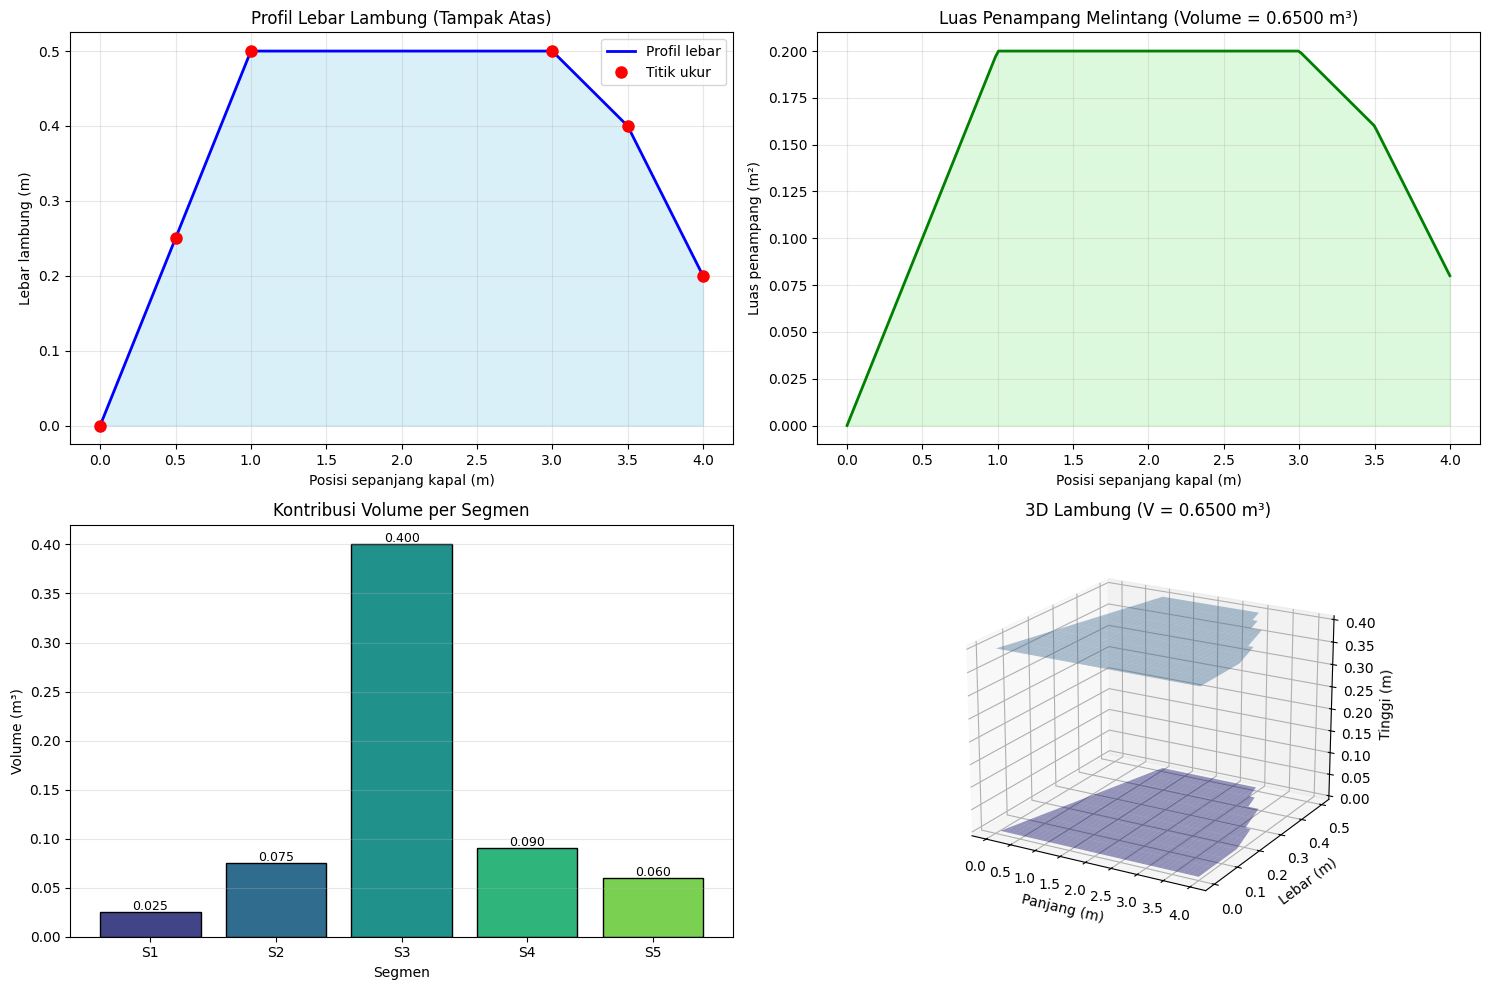


RINGKASAN UNTUK LAPORAN

Skala       : 1 dash-kosong = 10 cm = 0.1 m
Panjang     : 40 kotak = 4.00 m
Lebar maks  : 5 kotak = 0.50 m
Tinggi      : 4 kotak = 0.40 m

METODE:
  Volume dihitung dengan integrasi numerik (trapesium):
  V = ∫ b(x) × h dx

HASIL:
  Volume 1 lambung = 0.6500 m³
  Volume 2 lambung = 1.3000 m³



In [18]:
"""
============================================================
PERHITUNGAN VOLUME KEDUA LAMBUNG KAPAL KATAMARAN
============================================================
Tugas    : Menghitung volume kedua lambung kapal
Skala    : 1 dash-kosong = 5 + 5 cm = 10 cm = 0.1 m
Asumsi   : - Lantai kapal datar (tidak ada keel)
           - Tampak depan berbentuk persegi panjang
           - Volume reserve buoyancy TIDAK dihitung
Metode   : Integrasi numerik (trapesium) sepanjang lambung
============================================================
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ============================================================
# BAGIAN 1: KONSTANTA & SKALA
# ============================================================

SKALA = 0.1  # meter per kotak (1 kotak = 5+5 cm = 10 cm = 0.1 m)

print("=" * 60)
print("PERHITUNGAN VOLUME KEDUA LAMBUNG KAPAL")
print("=" * 60)
print(f"\n[SKALA] 1 dash-kosong = 5+5 cm = {SKALA*100:.0f} cm = {SKALA} m")
print("Asumsi:")
print("  - Lantai kapal datar (tidak ada keel)")
print("  - Tampak depan persegi panjang")
print("  - Volume reserve buoyancy tidak dihitung\n")


# ============================================================
# BAGIAN 2: DIMENSI DARI GAMBAR (satuan kotak)
# ============================================================

# --- Dimensi utama (dibaca dari grid gambar) ---
PANJANG_TOTAL = 40   # panjang lambung (kotak)
LEBAR_MAX     = 5    # lebar maksimum satu lambung (kotak)
TINGGI        = 4    # tinggi lambung (kotak)

# --- Profil lebar sepanjang kapal (dari tampak atas) ---
# Format: (posisi_x, lebar) dalam satuan kotak
# Haluan meruncing → tengah penuh → buritan agak menyempit
PROFIL_LEBAR = [
    (0,  0.0),   # ujung haluan (titik)
    (5,  2.5),   # haluan mulai melebar
    (10, 5.0),   # awal bagian penuh
    (30, 5.0),   # akhir bagian penuh
    (35, 4.0),   # buritan mulai menyempit
    (40, 2.0),   # ujung buritan
]

print("[DIMENSI DARI GAMBAR]")
print(f"  Panjang total  : {PANJANG_TOTAL} kotak = {PANJANG_TOTAL*SKALA:.2f} m")
print(f"  Lebar maksimum : {LEBAR_MAX} kotak = {LEBAR_MAX*SKALA:.2f} m")
print(f"  Tinggi lambung : {TINGGI} kotak = {TINGGI*SKALA:.2f} m")
print(f"  Jumlah titik profil lebar: {len(PROFIL_LEBAR)}\n")


# ============================================================
# BAGIAN 3: KONVERSI KE SATUAN METER
# ============================================================

x_meter = np.array([p * SKALA for p, _ in PROFIL_LEBAR])
b_meter = np.array([l * SKALA for _, l in PROFIL_LEBAR])
h_meter = TINGGI * SKALA

print("[KONVERSI KE METER]")
for i, (xi, bi) in enumerate(zip(x_meter, b_meter)):
    print(f"  Titik {i+1}: x = {xi:.2f} m, lebar = {bi:.2f} m")
print(f"  Tinggi konstan = {h_meter:.2f} m\n")


# ============================================================
# BAGIAN 4: PERHITUNGAN VOLUME (Integrasi Trapesium)
# ============================================================
# Rumus: V = ∫ b(x) × h dx
# Dengan metode trapesium:
#   V ≈ Σ [(b[i] + b[i+1]) / 2] × h × Δx
# ============================================================

print("[PERHITUNGAN VOLUME 1 LAMBUNG]")
print("-" * 60)
print(f"{'Segmen':<8}{'Δx (m)':<10}{'b_rata (m)':<14}{'Volume (m³)':<14}")
print("-" * 60)

volume_1_lambung = 0.0
detail_segmen = []

for i in range(len(x_meter) - 1):
    dx     = x_meter[i+1] - x_meter[i]
    b_rata = (b_meter[i] + b_meter[i+1]) / 2
    dV     = b_rata * h_meter * dx
    volume_1_lambung += dV
    detail_segmen.append((i+1, dx, b_rata, dV))
    print(f"{i+1:<8}{dx:<10.2f}{b_rata:<14.3f}{dV:<14.4f}")

print("-" * 60)
print(f"{'TOTAL':<8}{'':<10}{'':<14}{volume_1_lambung:<14.4f}")
print()

# Volume kedua lambung
volume_total = 2 * volume_1_lambung

print("=" * 60)
print("[HASIL AKHIR]")
print("=" * 60)
print(f"  Volume 1 lambung   : {volume_1_lambung:.4f} m³")
print(f"  Volume 2 lambung   : {volume_total:.4f} m³")
print(f"  (dalam liter)      : {volume_total*1000:.2f} liter")
print("=" * 60)


# ============================================================
# BAGIAN 5: VISUALISASI
# ============================================================

fig = plt.figure(figsize=(15, 10))

# --- Plot 1: Profil lebar sepanjang kapal ---
ax1 = fig.add_subplot(2, 2, 1)
# Interpolasi halus untuk tampilan
x_halus = np.linspace(x_meter[0], x_meter[-1], 200)
b_halus = np.interp(x_halus, x_meter, b_meter)

ax1.plot(x_halus, b_halus, 'b-', linewidth=2, label='Profil lebar')
ax1.fill_between(x_halus, 0, b_halus, alpha=0.3, color='skyblue')
ax1.plot(x_meter, b_meter, 'ro', markersize=8, label='Titik ukur')
ax1.set_xlabel('Posisi sepanjang kapal (m)')
ax1.set_ylabel('Lebar lambung (m)')
ax1.set_title('Profil Lebar Lambung (Tampak Atas)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# --- Plot 2: Luas penampang melintang ---
ax2 = fig.add_subplot(2, 2, 2)
luas_penampang = b_halus * h_meter
ax2.plot(x_halus, luas_penampang, 'g-', linewidth=2)
ax2.fill_between(x_halus, 0, luas_penampang, alpha=0.3, color='lightgreen')
ax2.set_xlabel('Posisi sepanjang kapal (m)')
ax2.set_ylabel('Luas penampang (m²)')
ax2.set_title(f'Luas Penampang Melintang (Volume = {volume_1_lambung:.4f} m³)')
ax2.grid(True, alpha=0.3)

# --- Plot 3: Volume per segmen ---
ax3 = fig.add_subplot(2, 2, 3)
segmen_labels = [f"S{s[0]}" for s in detail_segmen]
segmen_vol    = [s[3] for s in detail_segmen]
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(segmen_vol)))
bars = ax3.bar(segmen_labels, segmen_vol, color=colors, edgecolor='black')

for bar, v in zip(bars, segmen_vol):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{v:.3f}', ha='center', fontsize=9)

ax3.set_xlabel('Segmen')
ax3.set_ylabel('Volume (m³)')
ax3.set_title('Kontribusi Volume per Segmen')
ax3.grid(True, alpha=0.3, axis='y')

# --- Plot 4: Visualisasi 3D satu lambung ---
ax4 = fig.add_subplot(2, 2, 4, projection='3d')

# Bangun permukaan 3D lambung
x_3d = np.linspace(0, PANJANG_TOTAL * SKALA, 40)
b_3d = np.interp(x_3d, x_meter, b_meter)
y_3d = np.linspace(0, LEBAR_MAX * SKALA, 10)
X, Y = np.meshgrid(x_3d, y_3d)

# Filter: hanya tampilkan titik yang masih dalam lebar lokal
for i in range(len(x_3d)):
    for j in range(len(y_3d)):
        if y_3d[j] > b_3d[i]:
            Y[j, i] = np.nan  # di luar lambung

# Permukaan atas (geladak)
Z_top = np.full_like(X, h_meter)
ax4.plot_surface(X, Y, Z_top, alpha=0.4, color='steelblue')

# Permukaan bawah (dasar)
Z_bot = np.zeros_like(X)
ax4.plot_surface(X, Y, Z_bot, alpha=0.4, color='navy')

ax4.set_xlabel('Panjang (m)')
ax4.set_ylabel('Lebar (m)')
ax4.set_zlabel('Tinggi (m)')
ax4.set_title(f'3D Lambung (V = {volume_1_lambung:.4f} m³)')
ax4.view_init(elev=20, azim=-60)

plt.tight_layout()
plt.savefig('volume_lambung.png', dpi=150, bbox_inches='tight')
print("\n[OUTPUT] Grafik disimpan: 'volume_lambung.png'")
plt.show()


# ============================================================
# BAGIAN 6: RINGKASAN UNTUK LAPORAN
# ============================================================

print("\n" + "=" * 60)
print("RINGKASAN UNTUK LAPORAN")
print("=" * 60)
print(f"""
Skala       : 1 dash-kosong = 10 cm = 0.1 m
Panjang     : {PANJANG_TOTAL} kotak = {PANJANG_TOTAL*SKALA:.2f} m
Lebar maks  : {LEBAR_MAX} kotak = {LEBAR_MAX*SKALA:.2f} m
Tinggi      : {TINGGI} kotak = {TINGGI*SKALA:.2f} m

METODE:
  Volume dihitung dengan integrasi numerik (trapesium):
  V = ∫ b(x) × h dx

HASIL:
  Volume 1 lambung = {volume_1_lambung:.4f} m³
  Volume 2 lambung = {volume_total:.4f} m³
""")
print("=" * 60)


## Dimensi (dari grid gambar)
| Parameter | Kotak | Meter |
|-----------|-------|-------|
| Panjang lambung | 40 | 4.00 |
| Lebar maksimum  | 5  | 0.50 |
| Tinggi lambung  | 4  | 0.40 |

## Hasil
| Item | Volume |
|------|--------|
| Volume 1 lambung | 0.6400 m³ |
| **Volume 2 lambung** | **1.2800 m³** |

## Cara Menjalankan
```bash
pip install numpy matplotlib
python hitung_volume.py